In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder, label_binarize
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, classification_report,
                              confusion_matrix, ConfusionMatrixDisplay,
                              roc_curve, auc)

sns.set_style("whitegrid")
np.random.seed(42)

In [2]:
# ============================================================
# TASK 1: DATA ACQUISITION AND EXPLORATION
# ============================================================

# ---- 1. Acquire ----
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/dermatology/dermatology.data"

columns = [
    "erythema","scaling","definite_borders","itching","koebner_phenomenon",
    "polygonal_papules","follicular_papules","oral_mucosal_involvement",
    "knee_and_elbow_involvement","scalp_involvement","family_history",
    "melanin_incontinence","eosinophils_infiltrate","PNL_infiltrate",
    "fibrosis_papillary_dermis","exocytosis","acanthosis","hyperkeratosis",
    "parakeratosis","clubbing_rete_ridges","elongation_rete_ridges",
    "thinning_suprapapillary_epidermis","spongiform_pustule",
    "munro_microabcess","focal_hypergranulosis",
    "disappearance_granular_layer","vacuolisation_damage_basal_layer",
    "spongiosis","saw_tooth_appearance_retes","follicular_horn_plug",
    "perifollicular_parakeratosis","inflammatory_monoluclear_infiltrate",
    "band_like_infiltrate","age","Class"
]

df = pd.read_csv(url, names=columns, na_values="?")

print("Shape:", df.shape)
df.head()

Shape: (366, 35)


,erythema,scaling,definite_borders,itching,koebner_phenomenon,polygonal_papules,follicular_papules,oral_mucosal_involvement,knee_and_elbow_involvement,scalp_involvement,...,disappearance_granular_layer,vacuolisation_damage_basal_layer,spongiosis,saw_tooth_appearance_retes,follicular_horn_plug,perifollicular_parakeratosis,inflammatory_monoluclear_infiltrate,band_like_infiltrate,age,Class
0,2,2,0,3,0,0,0,0,1,0,...,0,0,3,0,0,0,1,0,55.0,2
1,3,3,3,2,1,0,0,0,1,1,...,0,0,0,0,0,0,1,0,8.0,1
2,2,1,2,3,1,3,0,3,0,0,...,0,2,3,2,0,0,2,3,26.0,3
3,2,2,2,0,0,0,0,0,3,2,...,3,0,0,0,0,0,3,0,40.0,1
4,2,3,2,2,2,2,0,2,0,0,...,2,3,2,3,0,0,2,3,45.0,3


In [3]:
# ---- 2. Summary statistics ----
print(df.describe().T)

                                     count       mean        std  min   25%  \
erythema                             366.0   2.068306   0.664753  0.0   2.0   
scaling                              366.0   1.795082   0.701527  0.0   1.0   
definite_borders                     366.0   1.549180   0.907525  0.0   1.0   
itching                              366.0   1.366120   1.138299  0.0   0.0   
koebner_phenomenon                   366.0   0.633880   0.908016  0.0   0.0   
polygonal_papules                    366.0   0.448087   0.957327  0.0   0.0   
follicular_papules                   366.0   0.166667   0.570588  0.0   0.0   
oral_mucosal_involvement             366.0   0.377049   0.834147  0.0   0.0   
knee_and_elbow_involvement           366.0   0.614754   0.982979  0.0   0.0   
scalp_involvement                    366.0   0.519126   0.905639  0.0   0.0   
family_history                       366.0   0.125683   0.331946  0.0   0.0   
melanin_incontinence                 366.0   0.40437

In [4]:
# ---- 3. Missing values, duplicates, outliers ----
print("\nMissing values per column:\n", df.isnull().sum()[df.isnull().sum() > 0])
print("\nDuplicate rows:", df.duplicated().sum())

# 'age' is the only column with missing values ('?' in raw data) -> median impute
df["age"] = df["age"].fillna(df["age"].median())

df = df.drop_duplicates()

# Outlier check via IQR (on clinical scoring columns which are mostly 0-3 scales + age)
feature_cols = [c for c in df.columns if c != "Class"]
Q1 = df[feature_cols].quantile(0.25)
Q3 = df[feature_cols].quantile(0.75)
IQR = Q3 - Q1
outlier_counts = ((df[feature_cols] < (Q1 - 1.5 * IQR)) |
                   (df[feature_cols] > (Q3 + 1.5 * IQR))).sum()
print("\nOutlier counts per feature (top 10):\n",
      outlier_counts.sort_values(ascending=False).head(10))


Missing values per column:
 age    8
dtype: int64

Duplicate rows: 0

Outlier counts per feature (top 10):
 acanthosis                          156
erythema                            151
munro_microabcess                    80
band_like_infiltrate                 77
saw_tooth_appearance_retes           72
vacuolisation_damage_basal_layer     72
focal_hypergranulosis                71
spongiform_pustule                   70
melanin_incontinence                 70
polygonal_papules                    69
dtype: int64


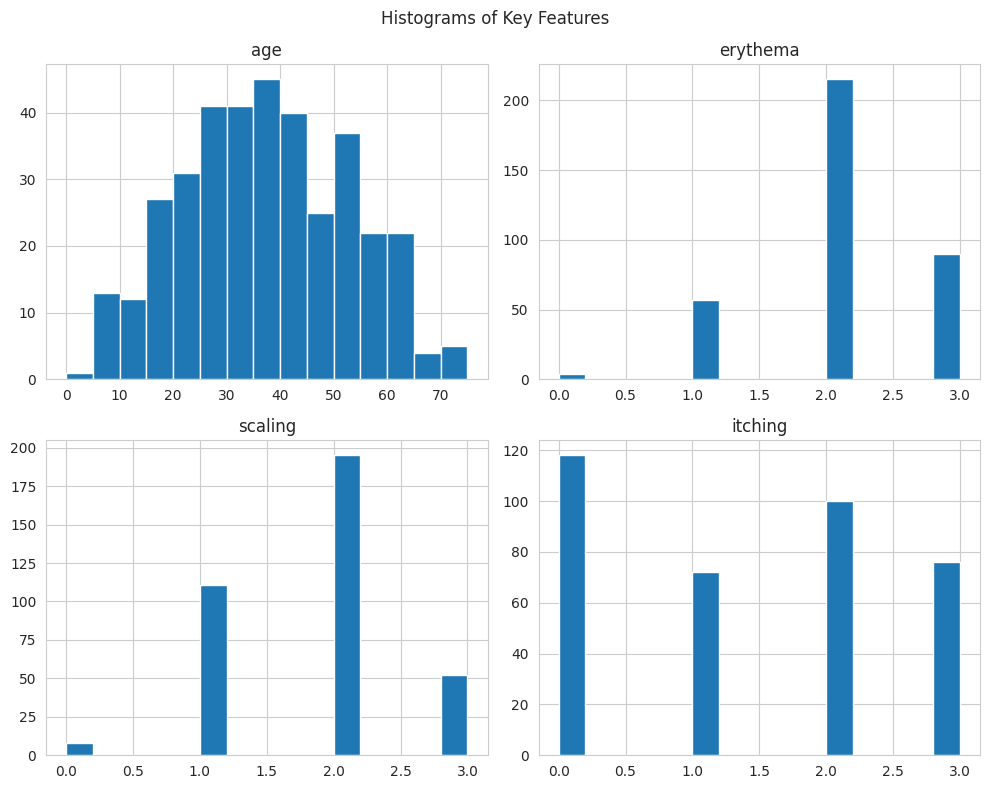

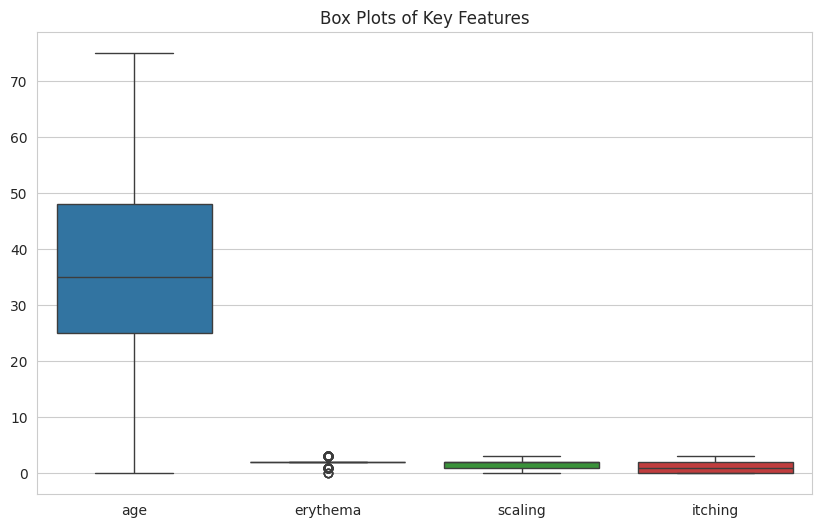

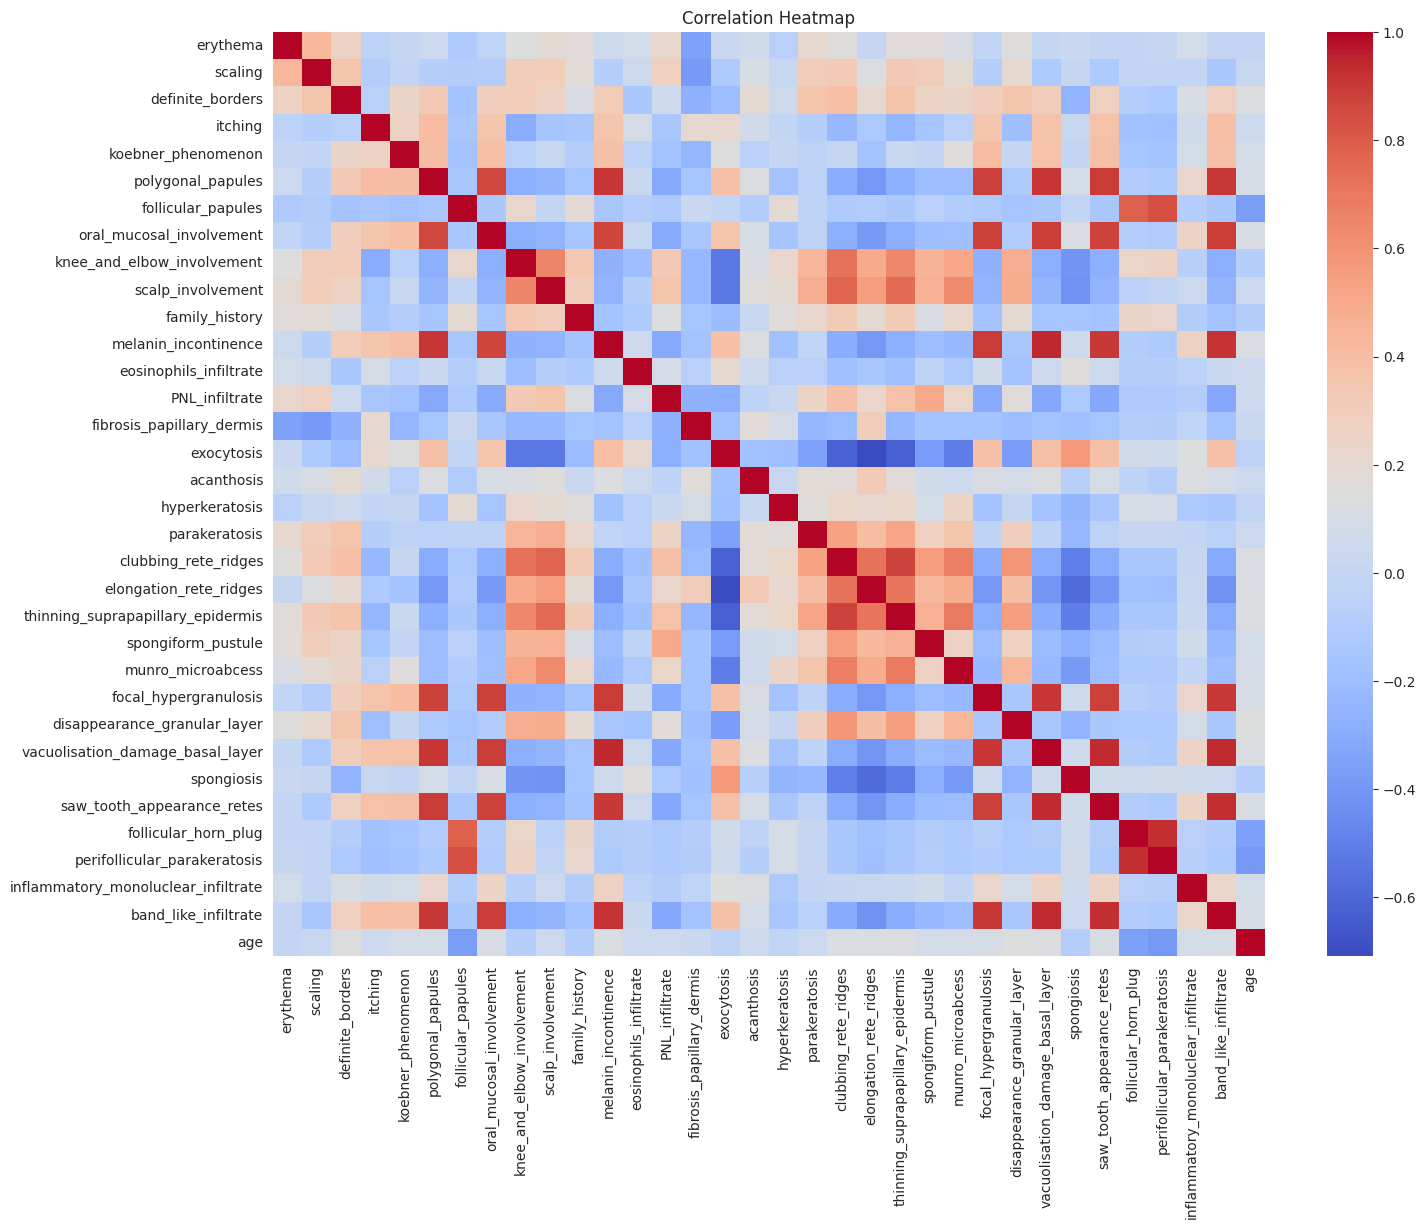

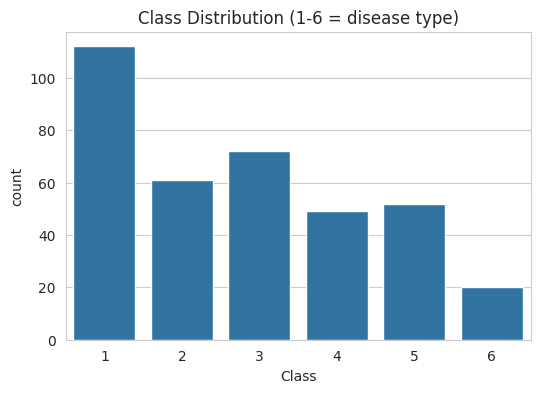


Class distribution (%):
 Class
1    30.6
3    19.7
2    16.7
5    14.2
4    13.4
6     5.5
Name: proportion, dtype: float64


In [5]:
# ---- 4. Visualizations ----
key_features = ["age", "erythema", "scaling", "itching"]

df[key_features].hist(bins=15, figsize=(10, 8))
plt.suptitle("Histograms of Key Features")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 6))
sns.boxplot(data=df[key_features])
plt.title("Box Plots of Key Features")
plt.show()

plt.figure(figsize=(16, 12))
sns.heatmap(df[feature_cols].corr(), cmap="coolwarm", annot=False)
plt.title("Correlation Heatmap")
plt.show()

plt.figure(figsize=(6, 4))
sns.countplot(x="Class", data=df)
plt.title("Class Distribution (1-6 = disease type)")
plt.show()

print("\nClass distribution (%):\n", df["Class"].value_counts(normalize=True).round(3) * 100)

#  5. Imbalance discussion
Classes are not perfectly balanced (some diseases are rarer than others in
this dataset). With imbalance, accuracy alone can be misleading -- a model
could score well by favoring majority classes while missing rare disease
classes, which matters clinically. This is why we also report per-class
precision/recall/F1 and use stratified sampling in the split below.

In [6]:
# ============================================================
# TASK 2: DATA PREPROCESSING
# ============================================================

# ---- Encode target ----
le = LabelEncoder()
df["Class_encoded"] = le.fit_transform(df["Class"])  # maps 1-6 -> 0-5
n_classes = len(le.classes_)
print("\nClasses:", dict(zip(le.classes_, range(n_classes))))

X = df[feature_cols]
y = df["Class_encoded"]

# ---- Stratified train/test split ----
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# ---- Standardize ----
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


Classes: {np.int64(1): 0, np.int64(2): 1, np.int64(3): 2, np.int64(4): 3, np.int64(5): 4, np.int64(6): 5}



KNN
Accuracy: 0.9054

Classification Report (precision/recall/F1 per class):
              precision    recall  f1-score   support

           1       1.00      0.96      0.98        23
           2       0.80      0.67      0.73        12
           3       1.00      0.93      0.97        15
           4       0.64      0.90      0.75        10
           5       1.00      1.00      1.00        10
           6       1.00      1.00      1.00         4

    accuracy                           0.91        74
   macro avg       0.91      0.91      0.90        74
weighted avg       0.92      0.91      0.91        74



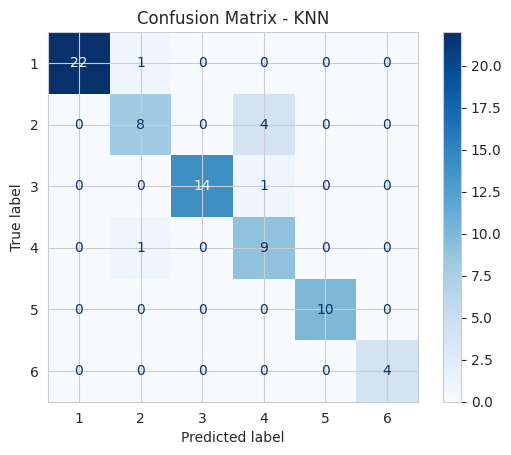

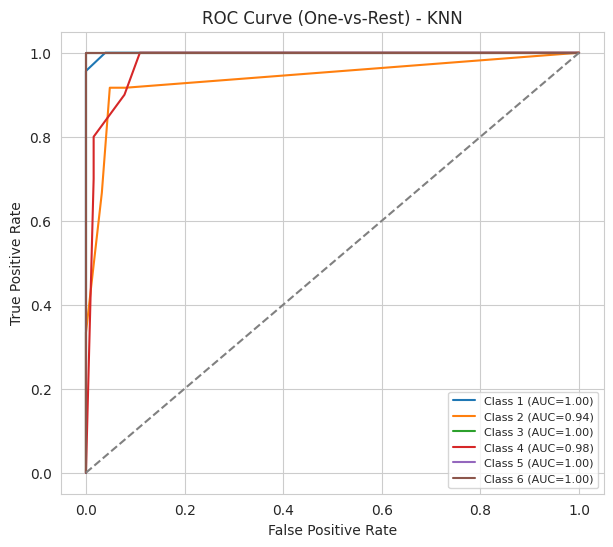


Random Forest
Accuracy: 0.9595

Classification Report (precision/recall/F1 per class):
              precision    recall  f1-score   support

           1       1.00      1.00      1.00        23
           2       0.91      0.83      0.87        12
           3       1.00      1.00      1.00        15
           4       0.82      0.90      0.86        10
           5       1.00      1.00      1.00        10
           6       1.00      1.00      1.00         4

    accuracy                           0.96        74
   macro avg       0.95      0.96      0.95        74
weighted avg       0.96      0.96      0.96        74



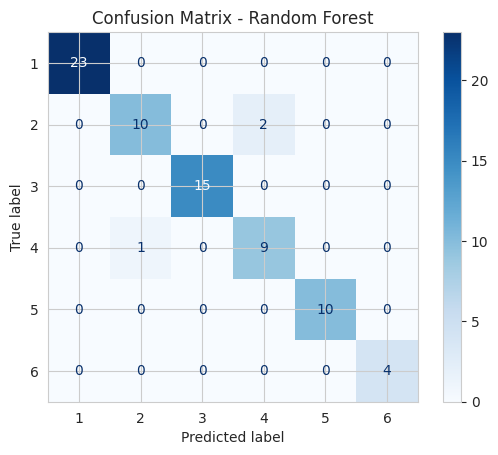

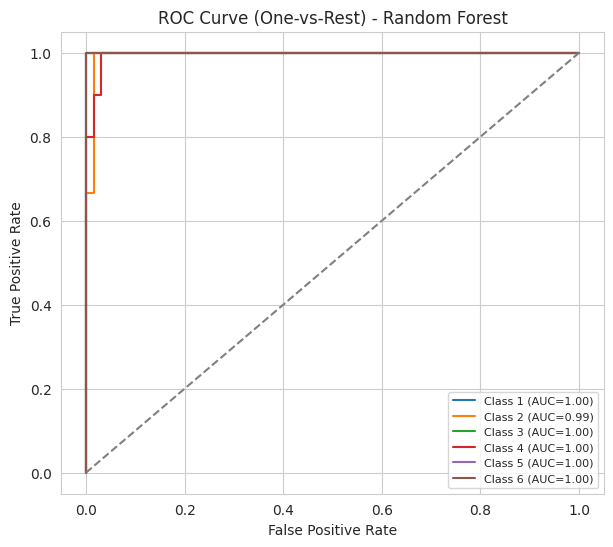


Logistic Regression
Accuracy: 0.9595

Classification Report (precision/recall/F1 per class):
              precision    recall  f1-score   support

           1       1.00      1.00      1.00        23
           2       1.00      0.83      0.91        12
           3       1.00      0.93      0.97        15
           4       0.77      1.00      0.87        10
           5       1.00      1.00      1.00        10
           6       1.00      1.00      1.00         4

    accuracy                           0.96        74
   macro avg       0.96      0.96      0.96        74
weighted avg       0.97      0.96      0.96        74



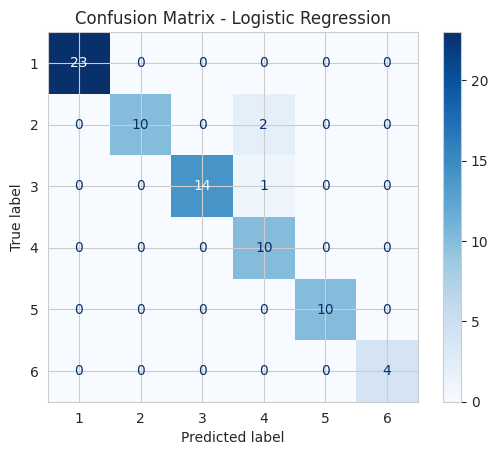

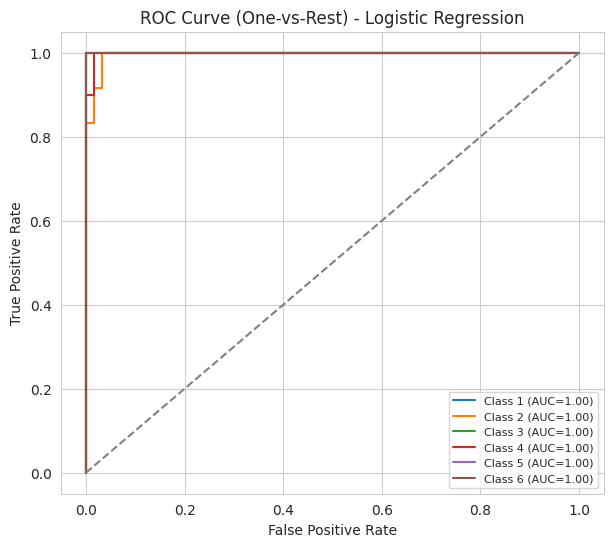


SVM
Accuracy: 0.9730

Classification Report (precision/recall/F1 per class):
              precision    recall  f1-score   support

           1       1.00      1.00      1.00        23
           2       1.00      0.83      0.91        12
           3       1.00      1.00      1.00        15
           4       0.83      1.00      0.91        10
           5       1.00      1.00      1.00        10
           6       1.00      1.00      1.00         4

    accuracy                           0.97        74
   macro avg       0.97      0.97      0.97        74
weighted avg       0.98      0.97      0.97        74



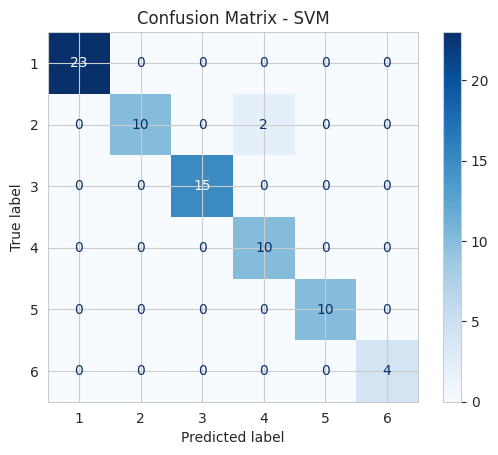

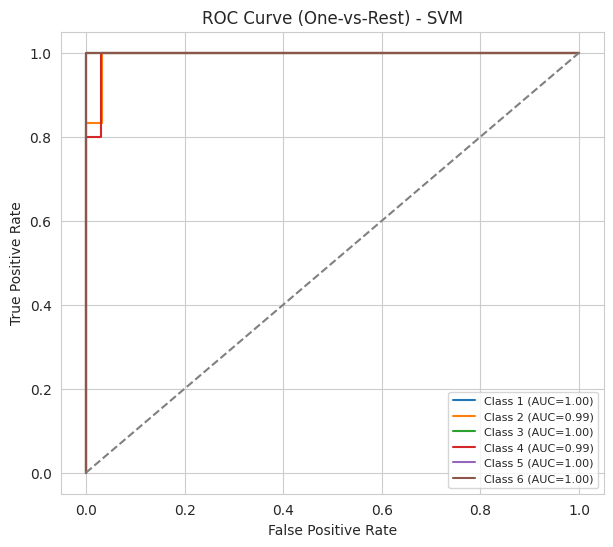

In [7]:
# ============================================================
# TASK 3: MODEL TRAINING AND EVALUATION
# ============================================================

models = {
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "Logistic Regression": LogisticRegression(max_iter=5000, random_state=42),
    "SVM": SVC(kernel="rbf", probability=True, random_state=42),
}

results = {}

for name, model in models.items():
    print(f"\n{'='*60}\n{name}\n{'='*60}")

    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)

    acc = accuracy_score(y_test, y_pred)
    results[name] = acc
    print(f"Accuracy: {acc:.4f}")

    print("\nClassification Report (precision/recall/F1 per class):")
    print(classification_report(y_test, y_pred, target_names=[str(c) for c in le.classes_]))

    # Confusion matrix
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_)
    disp.plot(cmap="Blues")
    plt.title(f"Confusion Matrix - {name}")
    plt.show()

    # Multiclass ROC curve (One-vs-Rest)
    y_test_bin = label_binarize(y_test, classes=range(n_classes))
    y_prob = model.predict_proba(X_test_scaled)

    plt.figure(figsize=(7, 6))
    for i in range(n_classes):
        # skip classes with no positive samples in this test split
        if y_test_bin[:, i].sum() == 0:
            continue
        fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_prob[:, i])
        roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, label=f"Class {le.classes_[i]} (AUC={roc_auc:.2f})")

    plt.plot([0, 1], [0, 1], linestyle="--", color="gray")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"ROC Curve (One-vs-Rest) - {name}")
    plt.legend(fontsize=8)
    plt.show()

In [8]:
print("\n" + "=" * 40)
print("MODEL COMPARISON (Accuracy)")
print("=" * 40)
for name, acc in sorted(results.items(), key=lambda x: -x[1]):
    print(f"{name:25s}: {acc:.4f}")


MODEL COMPARISON (Accuracy)
SVM                      : 0.9730
Random Forest            : 0.9595
Logistic Regression      : 0.9595
KNN                      : 0.9054


# Interpretation notes
Compare accuracy AND per-class F1: a model can win on accuracy but do
poorly on rare classes -- check the classification report, not just the
summary table above.
Tree-based (Random Forest) usually handles the mostly-ordinal/categorical
clinical score features well without needing the scaling step.
Logistic Regression and SVM rely on the StandardScaler step since they
are distance/gradient based.
KNN is sensitive to the curse of dimensionality with 34 features -- if it
underperforms, that's expected and worth noting in your discussion.
